In [1]:
'''
gotta make the white points in the html actually correspond to the transient
'''

'\ngotta make the white points in the html actually correspond to the transient\n'

In [3]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp

plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

Matplotlib is building the font cache; this may take a moment.


In [23]:
final_df = pd.read_csv('/lustre/lrspec/ZTF_data/final_df_july')

In [12]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [33]:
new_df

,Unnamed: 0.12,Unnamed: 0.11,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,...,ztf_ri_gaia_rp_mag,variability,in_vari_summary,point_left_brightening_denoised,point_right_brightening_denoised,point_left_dimming_denoised,point_right_dimming_denoised,point_left,point_right,FWHM
0,0,233662,233662,233662,233662,233662,233662,233662,233662,233662,...,9.714165,NOT_AVAILABLE,False,2636.0,2698.0,2701.0,2704.0,2636.0,2698.0,62.0
1,1,252593,252593,252593,252593,252593,252593,252593,252593,252593,...,10.077219,NOT_AVAILABLE,False,313.0,314.0,323.0,360.0,323.0,360.0,37.0
2,2,64793,64793,64793,64793,64793,64793,64793,64793,64793,...,7.530999,NOT_AVAILABLE,False,2391.0,2394.0,2355.0,2387.0,2355.0,2387.0,32.0
3,3,265333,265333,265333,265333,265333,265333,265333,265333,265333,...,7.965723,NOT_AVAILABLE,False,1978.0,1979.0,1925.0,1966.0,1925.0,1966.0,41.0
4,4,340170,340170,340170,340170,340170,340170,340170,340170,340170,...,8.536381,NOT_AVAILABLE,False,83.0,84.0,49.0,76.0,49.0,76.0,27.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,128618,128618,128618,128618,128618,128618,128618,128618,128618,...,7.645072,NOT_AVAILABLE,False,229.0,230.0,202.0,223.0,202.0,223.0,21.0
96,96,199793,199793,199793,199793,199793,199793,199793,199793,199793,...,9.224650,NOT_AVAILABLE,False,256.0,260.0,222.0,233.0,222.0,233.0,11.0
97,97,161233,161233,161233,161233,161233,161233,161233,161233,161233,...,6.620771,NOT_AVAILABLE,False,1353.0,1357.0,1365.0,1389.0,1365.0,1389.0,24.0
98,98,343159,343159,343159,343159,343159,343159,343159,343159,343159,...,7.870535,NOT_AVAILABLE,False,664.0,665.0,642.0,661.0,642.0,661.0,19.0


In [16]:
%matplotlib inline

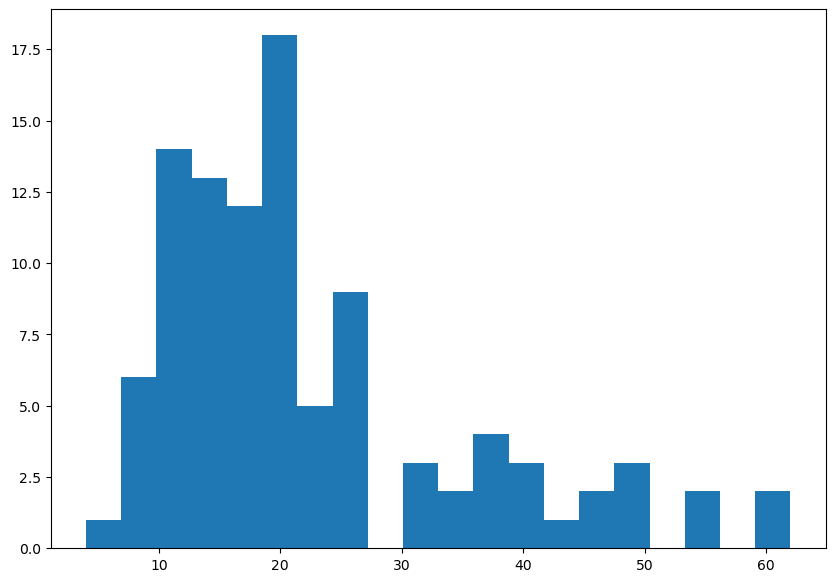

In [35]:
plt.hist(new_df['FWHM'], bins=20)
# plt.hist(final_df['snr_local_dimming_denoised'])
plt.show()

In [21]:
local_or_global='local'
for i, row in new_df.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        new_df.loc[i, 'point_left'] = new_df.loc[i, 'point_left_brightening_denoised']
        new_df.loc[i, 'point_right'] = new_df.loc[i, 'point_right_brightening_denoised']
    else:
        new_df.loc[i, 'point_left'] = new_df.loc[i, 'point_left_dimming_denoised']
        new_df.loc[i, 'point_right'] = new_df.loc[i, 'point_right_dimming_denoised']


In [13]:
new_df = rff.add_snr_both_denoised(final_df)

lightcurve_ztf_20221020138241_000686_zi_c12_x_0000_3_1175_0675_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_4_2557_1131_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_1_0911_2074_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c01_x_0000_1_1199_2475_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c16_x_0000_3_0332_2333_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c16_x_0000_3_0332_2333_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c01_x_0000_1_1781_1727_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c01_x_0000_1_0697_2833_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c02_x_0000_4_0658_2021_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c02_x_0000_3_0205_2290_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c02_x_0000_3_0246_1933_time_ad

/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrm

In [32]:
local_or_global='local'
for i, row in new_df.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        new_df.loc[i, 'FWHM'] = new_df.loc[i, 'FWHM_brightening_denoised']
    else:
        new_df.loc[i, 'FWHM'] = new_df.loc[i, 'FWHM_dimming_denoised']


In [31]:
new_df.columns[-40:]

Index(['snr_global', 'real_type_local', 'real_type_global',
       'distance_from_start', 'random_forest_result',
       'snr_local_brightening_denoised', 'snr_global_brightening_denoised',
       'noise_local_brightening_denoised', 'noise_global_brightening_denoised',
       'height_brightening_denoised', 'FWHM_brightening_denoised',
       'signal_local_brightening_denoised',
       'central_point_brightening_denoise', 'snr_local_dimming_denoised',
       'snr_global_dimming_denoised', 'noise_local_dimming_denoised',
       'noise_global_dimming_denoised',
       'local_average_outside_dimming_denoised', 'height_dimming_denoised',
       'FWHM_dimming_denoised', 'signal_local_dimming_denoised',
       'central_point_dimming_denoised', 'concat_index_copy',
       'snr_local_denoised', 'central_point', 'star_ra_x', 'star_dec_x',
       'star_ra_y', 'star_dec_y', 'gaia_source_id', 'ztf_g_gaia_bp_rp_mag',
       'ztf_ri_gaia_rp_mag', 'variability', 'in_vari_summary',
       'point_left_b

In [36]:
new_df.to_csv('/lustre/lrspec/ZTF_data/final_df_august')